# Lesson 6.9: Choosing the Right Test

Compare incomes (in thousands) in two cities with 12 people each: check the t-test assumptions, then run both the t-test and the Mann-Whitney test and decide which to trust.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## 1. Enter and look at the data

Skewed incomes in two cities, 12 people each. Always look first: each city has one very large income, which pulls its mean far above its median.

city A: mean = 50.4, median = 30.1, sd = 53.9
city B: mean = 94.1, median = 64.9, sd = 75.0


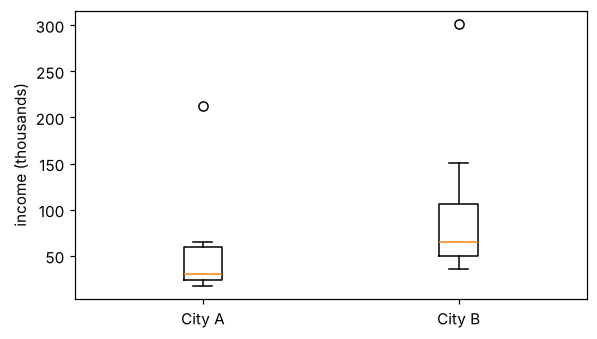

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

city_a = np.array([33.6, 26.6, 17.6, 64.6, 18.0, 23.9, 23.5, 23.2, 212.7, 39.8, 61.7, 59.1])
city_b = np.array([150.9, 42.3, 50.8, 36.2, 65.9, 95.3, 137.2, 45.7, 301.4, 50.7, 88.5, 63.9])

for name, g in [('A', city_a), ('B', city_b)]:
    print(f'city {name}: mean = {g.mean():.1f}, median = {np.median(g):.1f}, sd = {g.std(ddof=1):.1f}')

plt.figure(figsize=(6, 3.4))
plt.boxplot([city_a, city_b], tick_labels=['City A', 'City B'])
plt.ylabel('income (thousands)')
plt.show()

## 2. Check normality with Shapiro-Wilk

Shapiro-Wilk asks whether the data look like a sample from a normal curve. A p-value below 0.05 is evidence against normality. With only 12 per group, a normal-looking result would also not prove normality.

In [2]:
for name, g in [('A', city_a), ('B', city_b)]:
    w = stats.shapiro(g)
    verdict = 'not normal' if w.pvalue < 0.05 else 'no clear problem'
    print(f'city {name}: W = {w.statistic:.3f}, p = {w.pvalue:.4f} ({verdict})')

city A: W = 0.601, p = 0.0001 (not normal)
city B: W = 0.735, p = 0.0019 (not normal)


## 3. Check equal spread with Levene

Levene's test asks whether the two groups have the same spread. We use the mean-centred version so it matches SPSS and Stata (SciPy's default centres on the median). A small p-value would mean unequal spreads.

In [3]:
lev = stats.levene(city_a, city_b, center='mean')

print(f'Levene: statistic = {lev.statistic:.3f}, p = {lev.pvalue:.4f}')
print('spreads look equal?', lev.pvalue >= 0.05)

Levene: statistic = 0.931, p = 0.3452
spreads look equal? True


## 4. Run the t-test and Mann-Whitney

Welch's t-test compares means and is pulled around by the big incomes. The Mann-Whitney test uses ranks, so extreme values count only as 'the highest'. method='exact' gives an exact p-value when there are no ties.

In [4]:
t_res = stats.ttest_ind(city_a, city_b, equal_var=False)
u_res = stats.mannwhitneyu(city_a, city_b, method='exact', alternative='two-sided')

print(f'Welch t-test:   t = {t_res.statistic:.3f}, p = {t_res.pvalue:.4f}')
print(f'Mann-Whitney:   U = {u_res.statistic:.1f}, p = {u_res.pvalue:.4f}')

Welch t-test:   t = -1.638, p = 0.1170
Mann-Whitney:   U = 28.0, p = 0.0100


## 5. Decide which to trust

Both groups failed the normality check and n is small, so the rank-based test is the safer choice here. The two tests disagree at alpha = 0.05, which is a warning that outliers matter. Say which test you chose and why, before looking at p.

In [5]:
alpha = 0.05
print('t-test significant?      ', t_res.pvalue <= alpha)
print('Mann-Whitney significant?', u_res.pvalue <= alpha)
print()
print('Small, skewed samples: trust the Mann-Whitney result.')

t-test significant?       False
Mann-Whitney significant? True

Small, skewed samples: trust the Mann-Whitney result.


## Try this

- Change the largest income in city A (212.7) to 40 and predict how the t-test and Mann-Whitney p-values move.
- Add 100 to every value in city B (city_b + 100) and predict whether both tests become clearly significant.

## The same idea in R, SPSS and Stata

**R**

```r
a <- c(33.6, 26.6, 17.6, 64.6, 18, 23.9, 23.5, 23.2, 212.7, 39.8, 61.7, 59.1)
b <- c(150.9, 42.3, 50.8, 36.2, 65.9, 95.3, 137.2, 45.7, 301.4, 50.7, 88.5, 63.9)
shapiro.test(a); shapiro.test(b)

income <- c(a, b); city <- factor(rep(c("A", "B"), each = 12))
dev <- abs(income - ave(income, city))   # Levene = ANOVA on distances from the group mean
anova(lm(dev ~ city))

t.test(a, b)          # Welch
wilcox.test(a, b)     # Mann-Whitney (W equals U)
```

**SPSS** (Analyze > Descriptive Statistics > Explore (Plots > Normality plots with tests); Analyze > Compare Means > Independent-Samples T Test; Analyze > Nonparametric Tests > Legacy Dialogs > 2 Independent Samples)

```
DATA LIST FREE / city income.
BEGIN DATA
1 33.6 1 26.6 1 17.6 1 64.6 1 18 1 23.9
1 23.5 1 23.2 1 212.7 1 39.8 1 61.7 1 59.1
2 150.9 2 42.3 2 50.8 2 36.2 2 65.9 2 95.3
2 137.2 2 45.7 2 301.4 2 50.7 2 88.5 2 63.9
END DATA.
EXAMINE VARIABLES=income BY city
  /PLOT=NPPLOT.
T-TEST GROUPS=city(1 2)
  /VARIABLES=income.
NPAR TESTS
  /M-W=income BY city(1 2).
```

**Stata**

```
clear
set obs 24
generate city = 1 + (_n > 12)
generate income = real(word("33.6 26.6 17.6 64.6 18 23.9 23.5 23.2 212.7 39.8 61.7 59.1 150.9 42.3 50.8 36.2 65.9 95.3 137.2 45.7 301.4 50.7 88.5 63.9", _n))
swilk income if city == 1
swilk income if city == 2
robvar income, by(city)
ttest income, by(city) unequal
ranksum income, by(city)
```